# Gradient boosting

Import the libraries.


In [ ]:
import platform
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor


Load the dataset.


In [ ]:
MY_FILE = "air-quality.csv"
TARGET = "co_gt"
DROP = ["datetime", "nmhc_gt", "c6h6_gt", "nox_gt", "no2_gt", "absolute_humidity"]

raw = pd.read_csv(MY_FILE)
df = raw.drop(columns=DROP)


Uncomment the filter to use the first 12 calendar months.


In [ ]:
# df = raw.iloc[:8761, :] # create 12 months subset (2004-03-10 18:00:00 to 2005-03-10 18:00:00)
# df = df.drop(columns = DROP) #drop datetime
# df.tail()


,co_gt,pt08_s1_co,pt08_s2_nmhc,pt08_s3_nox,pt08_s4_no2,pt08_s5_o3,temperature_c,relative_humidity_pct
8756,2.1,1041,945,692,1082,1000,19.1,18.1
8757,2.2,1008,946,705,1016,942,19.5,15.3
8758,1.8,962,807,821,901,745,20.2,14.4
8759,1.9,1048,925,721,1022,941,19.8,16.0
8760,2.7,1145,1074,593,1186,1232,16.5,21.6


Remove excluded columns and handle missing values.


In [ ]:
df = df.replace(-200, np.nan)
df = df.dropna(subset=[TARGET])

X = df.drop(columns=[TARGET])
y = df[TARGET]

print("Usable rows:", len(df))
print("Input features:", X.columns.tolist())


Usable rows: 7097
Input features: ['pt08_s1_co', 'pt08_s2_nmhc', 'pt08_s3_nox', 'pt08_s4_no2', 'pt08_s5_o3', 'temperature_c', 'relative_humidity_pct']


Create the 80/20 split and five cross-validation folds.


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

cv = KFold(n_splits=5, shuffle=True, random_state=0)
METRIC = "neg_mean_absolute_error"

print("Training rows:", len(X_train))
print("Held-out test rows:", len(X_test))


Training rows: 5677
Held-out test rows: 1420


Build the preprocessing and gradient-boosting pipeline.


In [ ]:
gb_pipe = Pipeline([
    ("prep", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ])),
    ("model", GradientBoostingRegressor(random_state=0))
])


Search for the settings with the lowest cross-validation MAE.


In [ ]:
gb_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [5, 10]
}

search_gb = GridSearchCV(
    gb_pipe,
    gb_grid,
    cv=cv,
    scoring=METRIC,
    return_train_score=True,
    n_jobs=2,
    error_score="raise"
)

gb_search_start = perf_counter()
search_gb.fit(X_train, y_train)
gb_search_seconds = perf_counter() - gb_search_start


Display the best settings and validation results.


In [ ]:
gb_results = pd.DataFrame(search_gb.cv_results_)
gb_best = search_gb.best_index_

gb_summary = pd.DataFrame([{
    "Training MAE": -gb_results.loc[gb_best, "mean_train_score"],
    "CV MAE": -gb_results.loc[gb_best, "mean_test_score"],
    "CV MAE SD": gb_results.loc[gb_best, "std_test_score"],
    "Mean CV fit time (s)": gb_results.loc[gb_best, "mean_fit_time"]
}])

print("Best settings:", search_gb.best_params_)
print("MAE units: mg/m³")
print(gb_summary.round(4).to_string(index=False))


Best settings: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
MAE units: mg/m³
 Training MAE  CV MAE  CV MAE SD  Mean CV fit time (s)
       0.2779  0.3215     0.0128                3.0455


Measure fitting and prediction times on the current runtime.


In [ ]:
cpu = platform.processor() or platform.machine()
cpu_file = Path("/proc/cpuinfo")

if cpu_file.exists():
    cpu = next(
        (line.split(":", 1)[1].strip()
         for line in cpu_file.read_text().splitlines()
         if line.startswith("model name")),
        cpu
    )

print("Runtime:", platform.platform())
print("CPU:", cpu)
print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__)

# Measure a full training-set fit.
gb_model = clone(search_gb.best_estimator_)

gb_fit_start = perf_counter()
gb_model.fit(X_train, y_train)
gb_fit_seconds = perf_counter() - gb_fit_start


def gb_prediction_ms(model, data):
    model.predict(data)
    times = []

    for _ in range(20):
        start = perf_counter()
        model.predict(data)
        times.append(perf_counter() - start)

    return np.median(times) * 1000


gb_batch = X_train.iloc[:256]
gb_single_ms = gb_prediction_ms(gb_model, X_train.iloc[:1])
gb_batch_ms = gb_prediction_ms(gb_model, gb_batch)

gb_cost = pd.DataFrame([{
    "Search including refit (s)": gb_search_seconds,
    "Full training-set fit (s)": gb_fit_seconds,
    "Single-row prediction (ms)": gb_single_ms,
    "Batch rows": len(gb_batch),
    "Batch prediction (ms)": gb_batch_ms,
    "Batch ms per row": gb_batch_ms / len(gb_batch)
}])

print(gb_cost.round(4).to_string(index=False))


Runtime: Linux-6.6.159+-x86_64-with-glibc2.39
CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
Python: 3.13.18 | scikit-learn: 1.6.1
 Search including refit (s)  Full training-set fit (s)  Single-row prediction (ms)  Batch rows  Batch prediction (ms)  Batch ms per row
                    90.9023                      3.239                      2.3987         256                 3.5802             0.014


Compare training and validation MAE across the five folds.


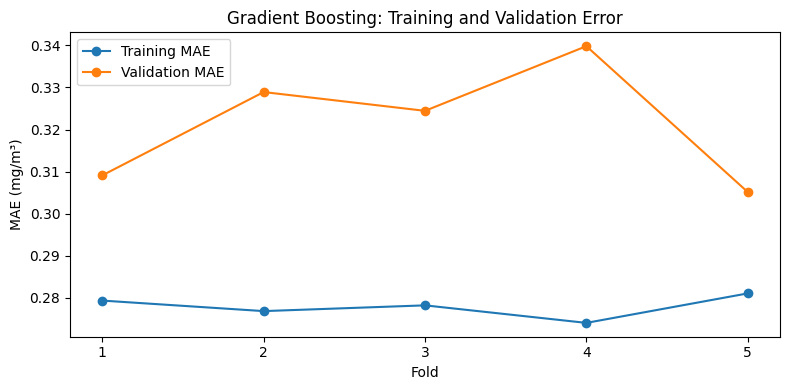

In [ ]:
gb_fold_results = pd.DataFrame({
    "Fold": range(1, cv.n_splits + 1),
    "Training MAE": [
        -search_gb.cv_results_[f"split{i}_train_score"][gb_best]
        for i in range(cv.n_splits)
    ],
    "Validation MAE": [
        -search_gb.cv_results_[f"split{i}_test_score"][gb_best]
        for i in range(cv.n_splits)
    ]
})

fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    gb_fold_results["Fold"],
    gb_fold_results["Training MAE"],
    "o-",
    label="Training MAE"
)

ax.plot(
    gb_fold_results["Fold"],
    gb_fold_results["Validation MAE"],
    "o-",
    label="Validation MAE"
)

ax.set_xticks(gb_fold_results["Fold"])
ax.set_xlabel("Fold")
ax.set_ylabel("MAE (mg/m³)")
ax.set_title("Gradient Boosting: Training and Validation Error")
ax.legend()

fig.tight_layout()
plt.show()
